In [3]:
def filter_midi(transcribed_midi, original_midi, time_tolerance=0.05, consider_offset=False, offset_tolerance=0.05):
    """
    Filter transcribed MIDI notes to keep only those that match original MIDI notes within a time tolerance.

    Args:
        transcribed_midi: pretty_midi.PrettyMIDI object of the transcribed MIDI
        original_midi: pretty_midi.PrettyMIDI object of the original MIDI
        time_tolerance: Time tolerance in seconds for matching note onsets
        consider_offset: If True, require the note end (offset) to match within
                         `offset_tolerance` as well. Default: False (we care only about onsets).
        offset_tolerance: Time tolerance in seconds for matching note offsets (end times)
    Returns:
        filtered_midi: pretty_midi.PrettyMIDI object with filtered notes
    """
    filtered_midi = pretty_midi.PrettyMIDI()
    for instrument in transcribed_midi.instruments:
        new_instrument = pretty_midi.Instrument(program=instrument.program, is_drum=instrument.is_drum)
        for note in instrument.notes:
            # Check if there is a matching note in the original MIDI within the time tolerance
            # Both pitch and onset timing must match; optionally also check the offset/duration
            note_matched = False
            for orig_instrument in original_midi.instruments:
                if note_matched:
                    break
                for orig_note in orig_instrument.notes:
                    if note.pitch != orig_note.pitch:
                        continue
                    if abs(note.start - orig_note.start) > time_tolerance:
                        continue
                    # If we reach here, onset and pitch match within tolerance
                    if consider_offset:
                        # require offset to match as well
                        if abs(note.end - orig_note.end) <= offset_tolerance:
                            new_instrument.notes.append(note)
                            note_matched = True
                            break
                        else:
                            # mismatch on offset -> do not accept this match
                            continue
                    else:
                        new_instrument.notes.append(note)
                        note_matched = True
                        break
        filtered_midi.instruments.append(new_instrument)
    return filtered_midi

In [4]:
import pretty_midi
import numpy as np

# Create a simplified synthetic original MIDI
original_midi = pretty_midi.PrettyMIDI()
original_instrument = pretty_midi.Instrument(program=0)

# Simple original notes
original_notes = [
    (60, 0.0, 1.0),   # C4 - será transcrito corretamente
    (64, 1.0, 2.0),   # E4 - será transcrito com duração errada (múltiplos onsets)
    (67, 2.0, 3.0),   # G4 - NÃO será transcrito (falso negativo)
    (72, 3.0, 4.0),   # C5 - será transcrito corretamente
]

for pitch, start, end in original_notes:
    note = pretty_midi.Note(velocity=80, pitch=pitch, start=start, end=end)
    original_instrument.notes.append(note)

original_midi.instruments.append(original_instrument)

# Create synthetic transcribed MIDI
transcribed_midi = pretty_midi.PrettyMIDI()
transcribed_instrument = pretty_midi.Instrument(program=0)

# Transcribed notes with various issues
transcribed_notes = [
    # C4 - transcrito corretamente
    (60, 0.02, 0.98),   # slight timing variation, should match
    
    # E4 - transcrito com duração errada (detectado múltiplas vezes)
    (64, 1.01, 1.25),   # primeira detecção
    (64, 1.3, 1.55),    # segunda detecção (onset errado)
    (64, 1.7, 1.95),    # terceira detecção (onset errado)
    
    # G4 - NÃO transcrito (falso negativo)
    # (sem entrada aqui)
    
    # C5 - transcrito corretamente
    (72, 3.02, 3.97),   # should match
    
    # Falsos positivos
    (69, 0.5, 0.8),     # A4 - não existe no original
    (74, 4.1, 4.4),     # D5 - não existe no original
]

for pitch, start, end in transcribed_notes:
    note = pretty_midi.Note(velocity=80, pitch=pitch, start=start, end=end)
    transcribed_instrument.notes.append(note)

transcribed_midi.instruments.append(transcribed_instrument)

# Test the filter function
filtered_no_offset = filter_midi(transcribed_midi, original_midi, time_tolerance=0.05, consider_offset=False)
filtered_with_offset = filter_midi(transcribed_midi, original_midi, time_tolerance=0.05, consider_offset=True, offset_tolerance=0.05)

print(f"Original MIDI notes: {len(original_midi.instruments[0].notes)}")
print(f"Transcribed MIDI notes: {len(transcribed_midi.instruments[0].notes)}")
print(f"Filtered (onsets only) notes: {len(filtered_no_offset.instruments[0].notes)}")
print(f"Filtered (onsets+offsets) notes: {len(filtered_with_offset.instruments[0].notes)}")

# Show detailed results
print("\nDetalhes das notas:")
print("Original:")
for i, note in enumerate(original_midi.instruments[0].notes):
    print(f"  {i+1}. Pitch {note.pitch}, {note.start:.2f}-{note.end:.2f}s")

print("\nTranscritas:")
for i, note in enumerate(transcribed_midi.instruments[0].notes):
    print(f"  {i+1}. Pitch {note.pitch}, {note.start:.2f}-{note.end:.2f}s")

print("\nFiltradas (onsets only):")
for i, note in enumerate(filtered_no_offset.instruments[0].notes):
    print(f"  {i+1}. Pitch {note.pitch}, {note.start:.2f}-{note.end:.2f}s")

print("\nFiltradas (onsets+offsets):")
for i, note in enumerate(filtered_with_offset.instruments[0].notes):
    print(f"  {i+1}. Pitch {note.pitch}, {note.start:.2f}-{note.end:.2f}s")


Original MIDI notes: 4
Transcribed MIDI notes: 7
Filtered (onsets only) notes: 3
Filtered (onsets+offsets) notes: 2

Detalhes das notas:
Original:
  1. Pitch 60, 0.00-1.00s
  2. Pitch 64, 1.00-2.00s
  3. Pitch 67, 2.00-3.00s
  4. Pitch 72, 3.00-4.00s

Transcritas:
  1. Pitch 60, 0.02-0.98s
  2. Pitch 64, 1.01-1.25s
  3. Pitch 64, 1.30-1.55s
  4. Pitch 64, 1.70-1.95s
  5. Pitch 72, 3.02-3.97s
  6. Pitch 69, 0.50-0.80s
  7. Pitch 74, 4.10-4.40s

Filtradas (onsets only):
  1. Pitch 60, 0.02-0.98s
  2. Pitch 64, 1.01-1.25s
  3. Pitch 72, 3.02-3.97s

Filtradas (onsets+offsets):
  1. Pitch 60, 0.02-0.98s
  2. Pitch 72, 3.02-3.97s


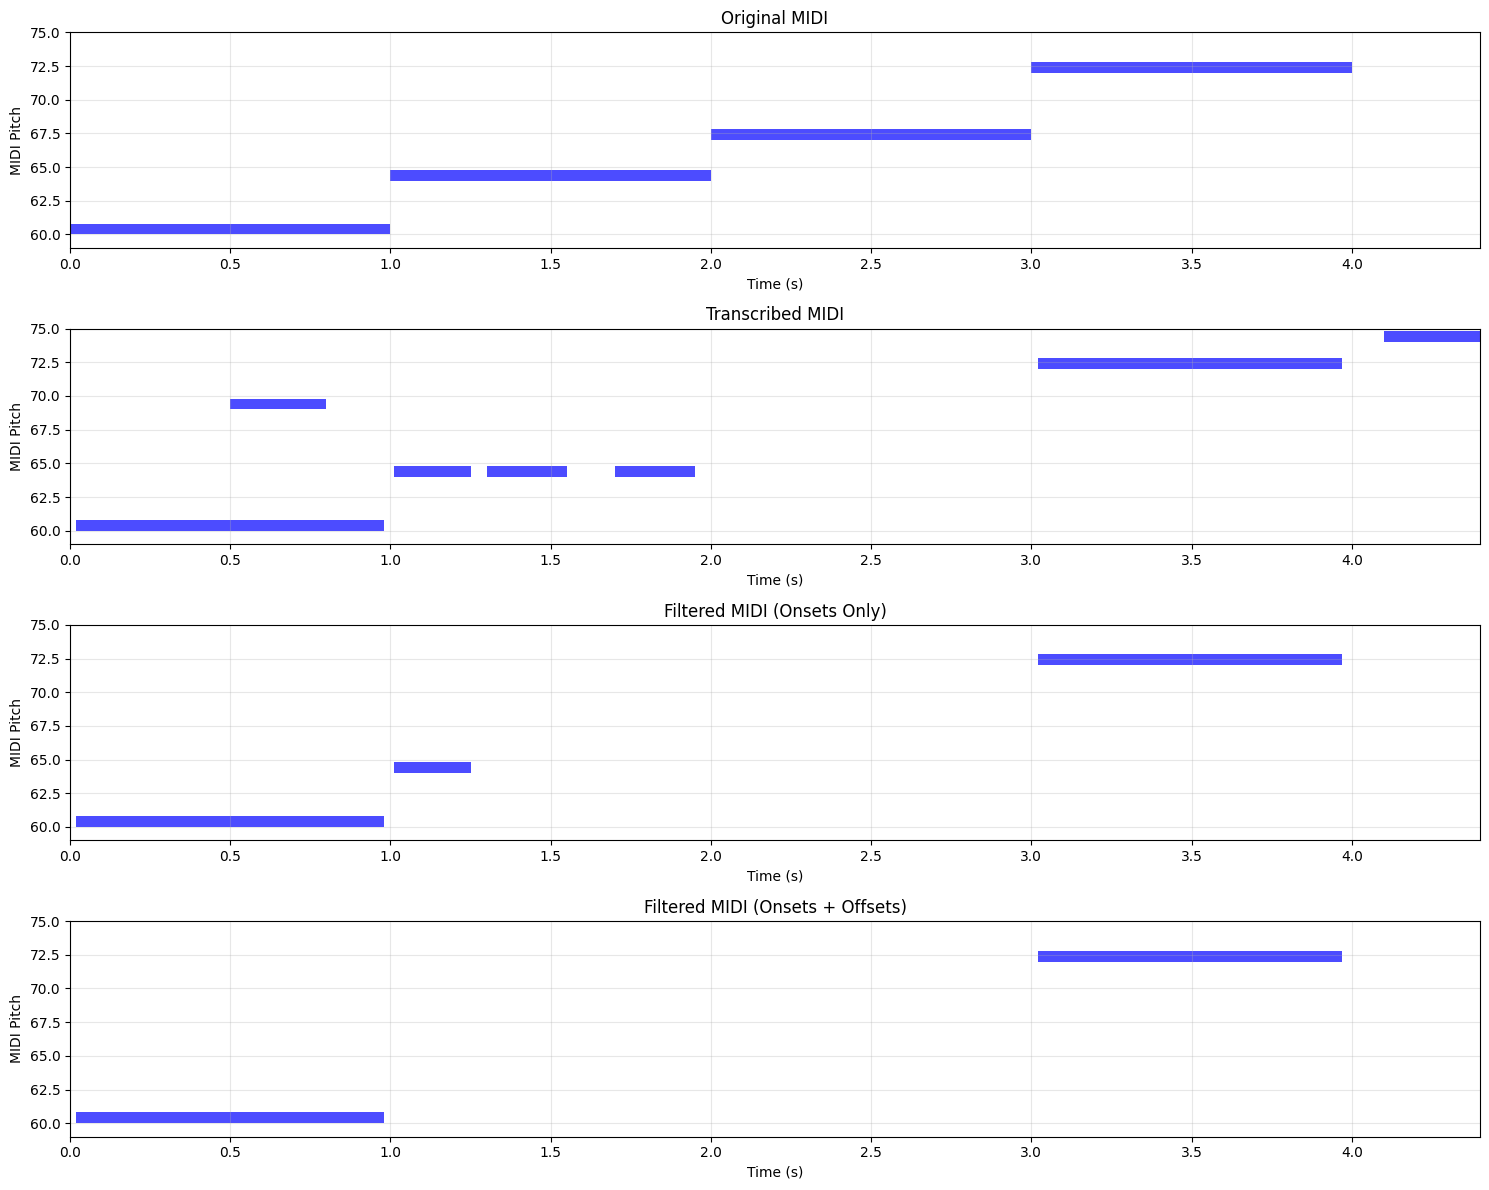

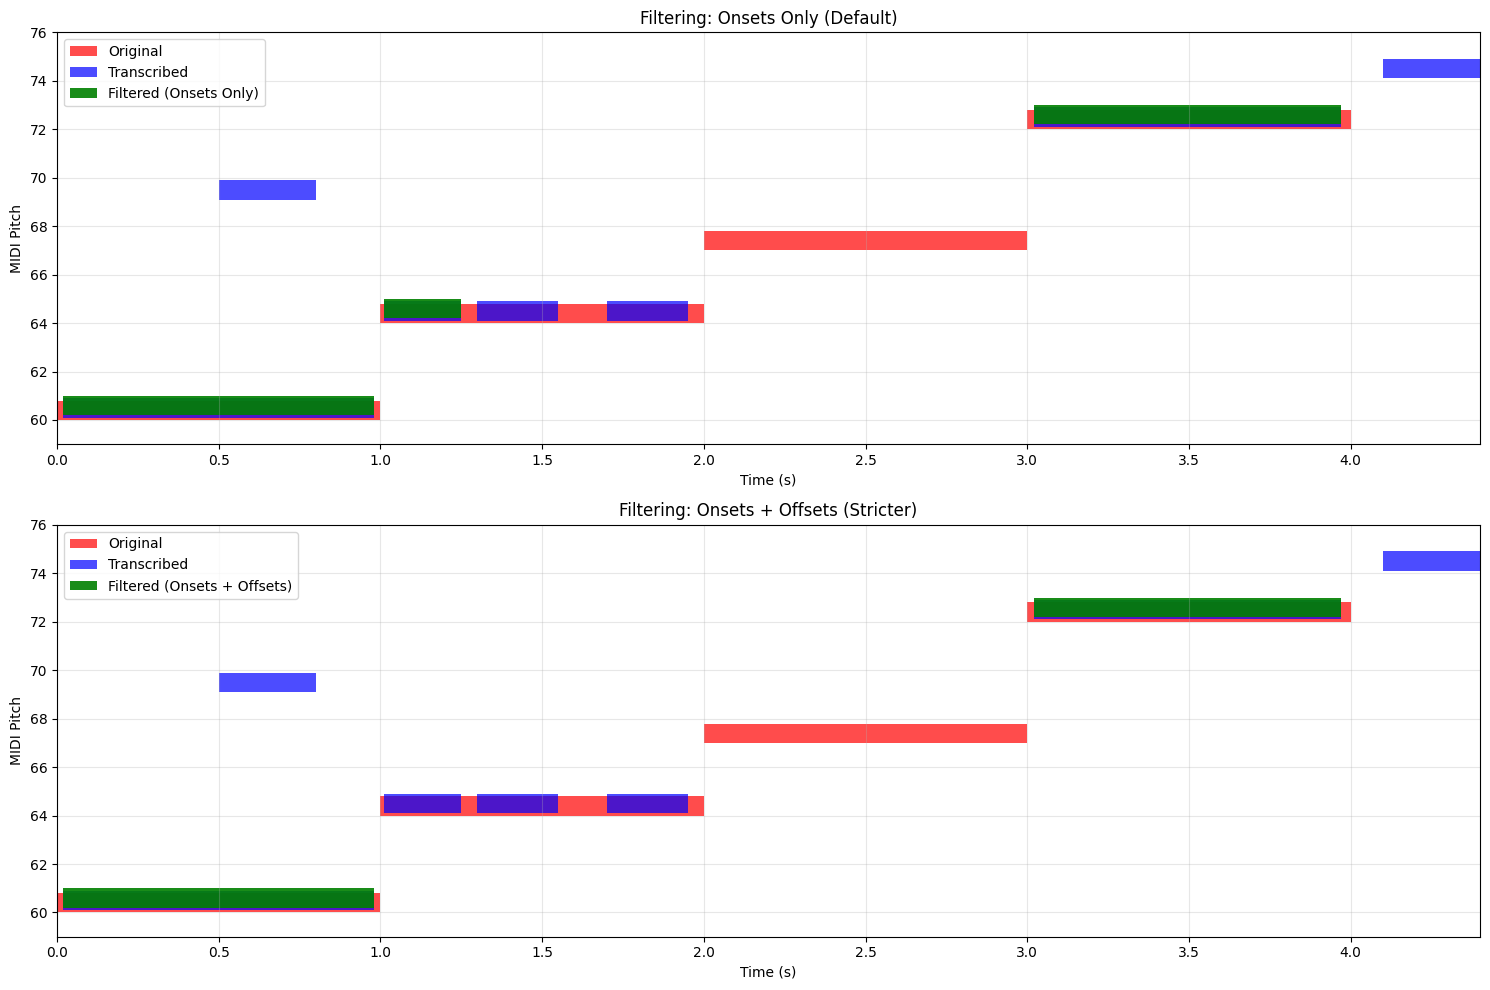

Original MIDI duration: 4.00s
Transcribed MIDI duration: 4.40s
Filtered (onsets only) duration: 3.97s
Filtered (onsets+offsets) duration: 3.97s
Common pitch range: 60 to 74


In [10]:
from matplotlib.patches import Patch
import matplotlib.pyplot as plt

# Define the plot_piano_roll function
def plot_piano_roll(midi, title, ax):
    for note in midi.instruments[0].notes:
        ax.add_patch(plt.Rectangle((note.start, note.pitch), 
                                  note.end - note.start, 0.8, 
                                  facecolor='blue', alpha=0.7))
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('MIDI Pitch')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

# Get all pitches from all MIDI files to determine common scale
all_pitches = []
for midi in [original_midi, transcribed_midi, filtered_no_offset, filtered_with_offset]:
    for note in midi.instruments[0].notes:
        all_pitches.append(note.pitch)

min_pitch = min(all_pitches)
max_pitch = max(all_pitches)

# Calculate total duration for each MIDI file
original_duration = original_midi.get_end_time()
transcribed_duration = transcribed_midi.get_end_time()
filtered_no_offset_duration = filtered_no_offset.get_end_time()
filtered_with_offset_duration = filtered_with_offset.get_end_time()

# Get the maximum duration to set consistent x-axis
max_duration = max(original_duration, transcribed_duration, filtered_no_offset_duration, filtered_with_offset_duration)

# Create subplots with full duration - showing both filtered versions
fig, axes = plt.subplots(4, 1, figsize=(15, 12))

# Plot each MIDI with full duration
plot_piano_roll(original_midi, 'Original MIDI', axes[0])
plot_piano_roll(transcribed_midi, 'Transcribed MIDI', axes[1])
plot_piano_roll(filtered_no_offset, 'Filtered MIDI (Onsets Only)', axes[2])
plot_piano_roll(filtered_with_offset, 'Filtered MIDI (Onsets + Offsets)', axes[3])

# Set consistent axis limits for all plots
for ax in axes:
    ax.set_xlim(0, max_duration)
    ax.set_ylim(min_pitch - 1, max_pitch + 1)

plt.tight_layout()

# Create combined plot comparing both filtering approaches
fig2, (ax2, ax3) = plt.subplots(2, 1, figsize=(15, 10))

# First plot: Onsets only filtering
# Plot original MIDI in red
for note in original_midi.instruments[0].notes:
    ax2.add_patch(plt.Rectangle((note.start, note.pitch), 
                              note.end - note.start, 0.8, 
                              facecolor='red', alpha=0.7))

# Plot transcribed MIDI in blue (slightly offset)
for note in transcribed_midi.instruments[0].notes:
    ax2.add_patch(plt.Rectangle((note.start, note.pitch + 0.1), 
                              note.end - note.start, 0.8, 
                              facecolor='blue', alpha=0.7))

# Plot filtered MIDI (onsets only) in green (on top)
for note in filtered_no_offset.instruments[0].notes:
    ax2.add_patch(plt.Rectangle((note.start, note.pitch + 0.2), 
                              note.end - note.start, 0.8, 
                              facecolor='green', alpha=0.9))

ax2.set_xlabel('Time (s)')
ax2.set_ylabel('MIDI Pitch')
ax2.set_title('Filtering: Onsets Only (Default)')
ax2.grid(True, alpha=0.3)
ax2.set_xlim(0, max_duration)
ax2.set_ylim(min_pitch - 1, max_pitch + 2)

# Create legend for first plot
legend_elements = [Patch(facecolor='red', alpha=0.7, label='Original'),
                   Patch(facecolor='blue', alpha=0.7, label='Transcribed'),
                   Patch(facecolor='green', alpha=0.9, label='Filtered (Onsets Only)')]
ax2.legend(handles=legend_elements)

# Second plot: Onsets + Offsets filtering
# Plot original MIDI in red
for note in original_midi.instruments[0].notes:
    ax3.add_patch(plt.Rectangle((note.start, note.pitch), 
                              note.end - note.start, 0.8, 
                              facecolor='red', alpha=0.7))

# Plot transcribed MIDI in blue (slightly offset)
for note in transcribed_midi.instruments[0].notes:
    ax3.add_patch(plt.Rectangle((note.start, note.pitch + 0.1), 
                              note.end - note.start, 0.8, 
                              facecolor='blue', alpha=0.7))

# Plot filtered MIDI (onsets + offsets) in green (on top)
for note in filtered_with_offset.instruments[0].notes:
    ax3.add_patch(plt.Rectangle((note.start, note.pitch + 0.2), 
                              note.end - note.start, 0.8, 
                              facecolor='green', alpha=0.9))

ax3.set_xlabel('Time (s)')
ax3.set_ylabel('MIDI Pitch')
ax3.set_title('Filtering: Onsets + Offsets (Stricter)')
ax3.grid(True, alpha=0.3)
ax3.set_xlim(0, max_duration)
ax3.set_ylim(min_pitch - 1, max_pitch + 2)

# Create legend for second plot
legend_elements2 = [Patch(facecolor='red', alpha=0.7, label='Original'),
                    Patch(facecolor='blue', alpha=0.7, label='Transcribed'),
                    Patch(facecolor='green', alpha=0.9, label='Filtered (Onsets + Offsets)')]
ax3.legend(handles=legend_elements2)

plt.tight_layout()
plt.show()

print(f"Original MIDI duration: {original_duration:.2f}s")
print(f"Transcribed MIDI duration: {transcribed_duration:.2f}s")
print(f"Filtered (onsets only) duration: {filtered_no_offset_duration:.2f}s")
print(f"Filtered (onsets+offsets) duration: {filtered_with_offset_duration:.2f}s")
print(f"Common pitch range: {min_pitch} to {max_pitch}")

In [11]:
# Vamos analisar as correspondências manualmente
print("Análise detalhada das correspondências:")
print("="*50)

# Vamos ver quais notas transcritas correspondem a quais originais
matches = []
for i, trans_note in enumerate(transcribed_midi.instruments[0].notes):
    for j, orig_note in enumerate(original_midi.instruments[0].notes):
        if (trans_note.pitch == orig_note.pitch and 
            abs(trans_note.start - orig_note.start) <= 0.05):
            matches.append((i+1, j+1, trans_note.pitch, trans_note.start, orig_note.start))
            print(f"Transcribed #{i+1:2d} (Pitch {trans_note.pitch}, start {trans_note.start:.2f}) -> Original #{j+1:2d} (start {orig_note.start:.2f})")

print(f"\nTotal de correspondências encontradas: {len(matches)}")
print(f"Total de notas originais: {len(original_midi.instruments[0].notes)}")

# Vamos ver se há correspondências duplas
transcribed_used = set()
for match in matches:
    trans_idx = match[0]
    if trans_idx in transcribed_used:
        print(f"ATENÇÃO: Nota transcrita #{trans_idx} já foi usada!")
    transcribed_used.add(trans_idx)

Análise detalhada das correspondências:
Transcribed # 1 (Pitch 60, start 0.02) -> Original # 1 (start 0.00)
Transcribed # 2 (Pitch 64, start 1.01) -> Original # 2 (start 1.00)
Transcribed # 5 (Pitch 72, start 3.02) -> Original # 4 (start 3.00)

Total de correspondências encontradas: 3
Total de notas originais: 4


In [5]:
# Importar as funções de cálculo de erro
import sys
sys.path.append('.')
from onset_detection_simple import get_onsets_from_midi, get_onsets_from_midi_by_note
from metric import mean_absolute_onset_error, note_based_onset_error

print("Testando diferentes métodos de cálculo de erro de onset")
print("="*60)

# 1. Extrair onsets agrupados (método tradicional)
original_onsets = get_onsets_from_midi(original_midi, combine=0.03)
transcribed_onsets = get_onsets_from_midi(transcribed_midi, combine=0.03)
filtered_no_offset_onsets = get_onsets_from_midi(filtered_no_offset, combine=0.03)
filtered_with_offset_onsets = get_onsets_from_midi(filtered_with_offset, combine=0.03)

print("MÉTODO 1: ONSETS AGRUPADOS")
print("-"*30)
print(f"Original onsets: {original_onsets}")
print(f"Transcribed onsets: {transcribed_onsets}")
print(f"Filtered (no offset) onsets: {filtered_no_offset_onsets}")
print(f"Filtered (with offset) onsets: {filtered_with_offset_onsets}")

# Calcular erros com método tradicional
error_original_vs_transcribed = mean_absolute_onset_error(original_onsets, transcribed_onsets, window=0.05)
error_original_vs_filtered_no_offset = mean_absolute_onset_error(original_onsets, filtered_no_offset_onsets, window=0.05)
error_original_vs_filtered_with_offset = mean_absolute_onset_error(original_onsets, filtered_with_offset_onsets, window=0.05)

print(f"\nErros (método agrupado):")
print(f"Original vs Transcribed: {error_original_vs_transcribed:.4f}s")
print(f"Original vs Filtered (no offset): {error_original_vs_filtered_no_offset:.4f}s") 
print(f"Original vs Filtered (with offset): {error_original_vs_filtered_with_offset:.4f}s")

Testando diferentes métodos de cálculo de erro de onset
MÉTODO 1: ONSETS AGRUPADOS
------------------------------
Original onsets: [0.0, 1.0, 2.0, 3.0]
Transcribed onsets: [0.02, 0.5, 1.01, 1.3, 1.7, 3.02, 4.1]
Filtered (no offset) onsets: [0.02, 1.01, 3.02]
Filtered (with offset) onsets: [0.02, 3.02]

Erros (método agrupado):
Original vs Transcribed: 0.0167s
Original vs Filtered (no offset): 0.0167s
Original vs Filtered (with offset): 0.0200s


In [6]:
# 2. Extrair onsets por nota (método novo)
original_notes_data = get_onsets_from_midi_by_note(original_midi, combine=0.03)
transcribed_notes_data = get_onsets_from_midi_by_note(transcribed_midi, combine=0.03)
filtered_no_offset_notes_data = get_onsets_from_midi_by_note(filtered_no_offset, combine=0.03)
filtered_with_offset_notes_data = get_onsets_from_midi_by_note(filtered_with_offset, combine=0.03)

print("\nMÉTODO 2: ONSETS POR NOTA")
print("-"*30)
print(f"Original notes: {len(original_notes_data)} notas")
for i, note in enumerate(original_notes_data):
    print(f"  {i+1}. Pitch {note['pitch']}, onset {note['onset']:.3f}s, duration {note['duration']:.3f}s")

print(f"\nTranscribed notes: {len(transcribed_notes_data)} notas")
for i, note in enumerate(transcribed_notes_data):
    print(f"  {i+1}. Pitch {note['pitch']}, onset {note['onset']:.3f}s, duration {note['duration']:.3f}s")

print(f"\nFiltered (no offset) notes: {len(filtered_no_offset_notes_data)} notas")
for i, note in enumerate(filtered_no_offset_notes_data):
    print(f"  {i+1}. Pitch {note['pitch']}, onset {note['onset']:.3f}s, duration {note['duration']:.3f}s")

print(f"\nFiltered (with offset) notes: {len(filtered_with_offset_notes_data)} notas")
for i, note in enumerate(filtered_with_offset_notes_data):
    print(f"  {i+1}. Pitch {note['pitch']}, onset {note['onset']:.3f}s, duration {note['duration']:.3f}s")

# Calcular erros com método por nota
error_note_original_vs_transcribed = note_based_onset_error(original_notes_data, transcribed_notes_data, window=0.05)
error_note_original_vs_filtered_no_offset = note_based_onset_error(original_notes_data, filtered_no_offset_notes_data, window=0.05)
error_note_original_vs_filtered_with_offset = note_based_onset_error(original_notes_data, filtered_with_offset_notes_data, window=0.05)

print(f"\nErros (método por nota):")
print(f"Original vs Transcribed:")
print(f"  Matched: {error_note_original_vs_transcribed['matched_count']}/{error_note_original_vs_transcribed['total_reference']}")
print(f"  Mean error: {error_note_original_vs_transcribed['mean_error']:.4f}s")
print(f"  Individual errors: {error_note_original_vs_transcribed['note_errors']}")

print(f"\nOriginal vs Filtered (no offset):")
print(f"  Matched: {error_note_original_vs_filtered_no_offset['matched_count']}/{error_note_original_vs_filtered_no_offset['total_reference']}")
print(f"  Mean error: {error_note_original_vs_filtered_no_offset['mean_error']:.4f}s")
print(f"  Individual errors: {error_note_original_vs_filtered_no_offset['note_errors']}")

print(f"\nOriginal vs Filtered (with offset):")
print(f"  Matched: {error_note_original_vs_filtered_with_offset['matched_count']}/{error_note_original_vs_filtered_with_offset['total_reference']}")
print(f"  Mean error: {error_note_original_vs_filtered_with_offset['mean_error']:.4f}s")
print(f"  Individual errors: {error_note_original_vs_filtered_with_offset['note_errors']}")


MÉTODO 2: ONSETS POR NOTA
------------------------------
Original notes: 4 notas
  1. Pitch 60, onset 0.000s, duration 1.000s
  2. Pitch 64, onset 1.000s, duration 1.000s
  3. Pitch 67, onset 2.000s, duration 1.000s
  4. Pitch 72, onset 3.000s, duration 1.000s

Transcribed notes: 7 notas
  1. Pitch 60, onset 0.020s, duration 0.960s
  2. Pitch 69, onset 0.500s, duration 0.300s
  3. Pitch 64, onset 1.010s, duration 0.240s
  4. Pitch 64, onset 1.300s, duration 0.250s
  5. Pitch 64, onset 1.700s, duration 0.250s
  6. Pitch 72, onset 3.020s, duration 0.950s
  7. Pitch 74, onset 4.100s, duration 0.300s

Filtered (no offset) notes: 3 notas
  1. Pitch 60, onset 0.020s, duration 0.960s
  2. Pitch 64, onset 1.010s, duration 0.240s
  3. Pitch 72, onset 3.020s, duration 0.950s

Filtered (with offset) notes: 2 notas
  1. Pitch 60, onset 0.020s, duration 0.960s
  2. Pitch 72, onset 3.020s, duration 0.950s

Erros (método por nota):
Original vs Transcribed:
  Matched: 3/4
  Mean error: 0.0167s
  Indi

In [7]:
# 3. Análise e comparação das métricas
print("\n" + "="*60)
print("COMPARAÇÃO DOS MÉTODOS DE CÁLCULO DE ERRO")
print("="*60)

# Criar tabela comparativa
import pandas as pd

# Dados para comparação
comparison_data = {
    'Método': ['Agrupado', 'Agrupado', 'Agrupado', 'Por Nota', 'Por Nota', 'Por Nota'],
    'Comparação': [
        'Original vs Transcribed', 
        'Original vs Filtered (no offset)', 
        'Original vs Filtered (with offset)',
        'Original vs Transcribed', 
        'Original vs Filtered (no offset)', 
        'Original vs Filtered (with offset)'
    ],
    'Erro Médio (s)': [
        error_original_vs_transcribed if error_original_vs_transcribed is not None else float('nan'),
        error_original_vs_filtered_no_offset if error_original_vs_filtered_no_offset is not None else float('nan'),
        error_original_vs_filtered_with_offset if error_original_vs_filtered_with_offset is not None else float('nan'),
        error_note_original_vs_transcribed['mean_error'] if error_note_original_vs_transcribed['mean_error'] is not None else float('nan'),
        error_note_original_vs_filtered_no_offset['mean_error'] if error_note_original_vs_filtered_no_offset['mean_error'] is not None else float('nan'),
        error_note_original_vs_filtered_with_offset['mean_error'] if error_note_original_vs_filtered_with_offset['mean_error'] is not None else float('nan')
    ],
    'Notas Matched': [
        'N/A',  # Método agrupado não reporta matches individuais
        'N/A',
        'N/A', 
        f"{error_note_original_vs_transcribed['matched_count']}/{error_note_original_vs_transcribed['total_reference']}",
        f"{error_note_original_vs_filtered_no_offset['matched_count']}/{error_note_original_vs_filtered_no_offset['total_reference']}",
        f"{error_note_original_vs_filtered_with_offset['matched_count']}/{error_note_original_vs_filtered_with_offset['total_reference']}"
    ]
}

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison.to_string(index=False))

print(f"\nOBSERVAÇÕES:")
print(f"1. Método Agrupado: Combina onsets próximos e calcula erro médio dos matches")
print(f"2. Método Por Nota: Analisa cada nota individualmente, considera pitch + timing")
print(f"3. O filtro 'with offset' é mais restritivo e deveria ter menos matches")
print(f"4. Valores 'None' indicam que não houve matches suficientes para calcular erro")


COMPARAÇÃO DOS MÉTODOS DE CÁLCULO DE ERRO
  Método                         Comparação  Erro Médio (s) Notas Matched
Agrupado            Original vs Transcribed        0.016667           N/A
Agrupado   Original vs Filtered (no offset)        0.016667           N/A
Agrupado Original vs Filtered (with offset)        0.020000           N/A
Por Nota            Original vs Transcribed        0.016667           3/4
Por Nota   Original vs Filtered (no offset)        0.016667           3/4
Por Nota Original vs Filtered (with offset)        0.020000           2/4

OBSERVAÇÕES:
1. Método Agrupado: Combina onsets próximos e calcula erro médio dos matches
2. Método Por Nota: Analisa cada nota individualmente, considera pitch + timing
3. O filtro 'with offset' é mais restritivo e deveria ter menos matches
4. Valores 'None' indicam que não houve matches suficientes para calcular erro


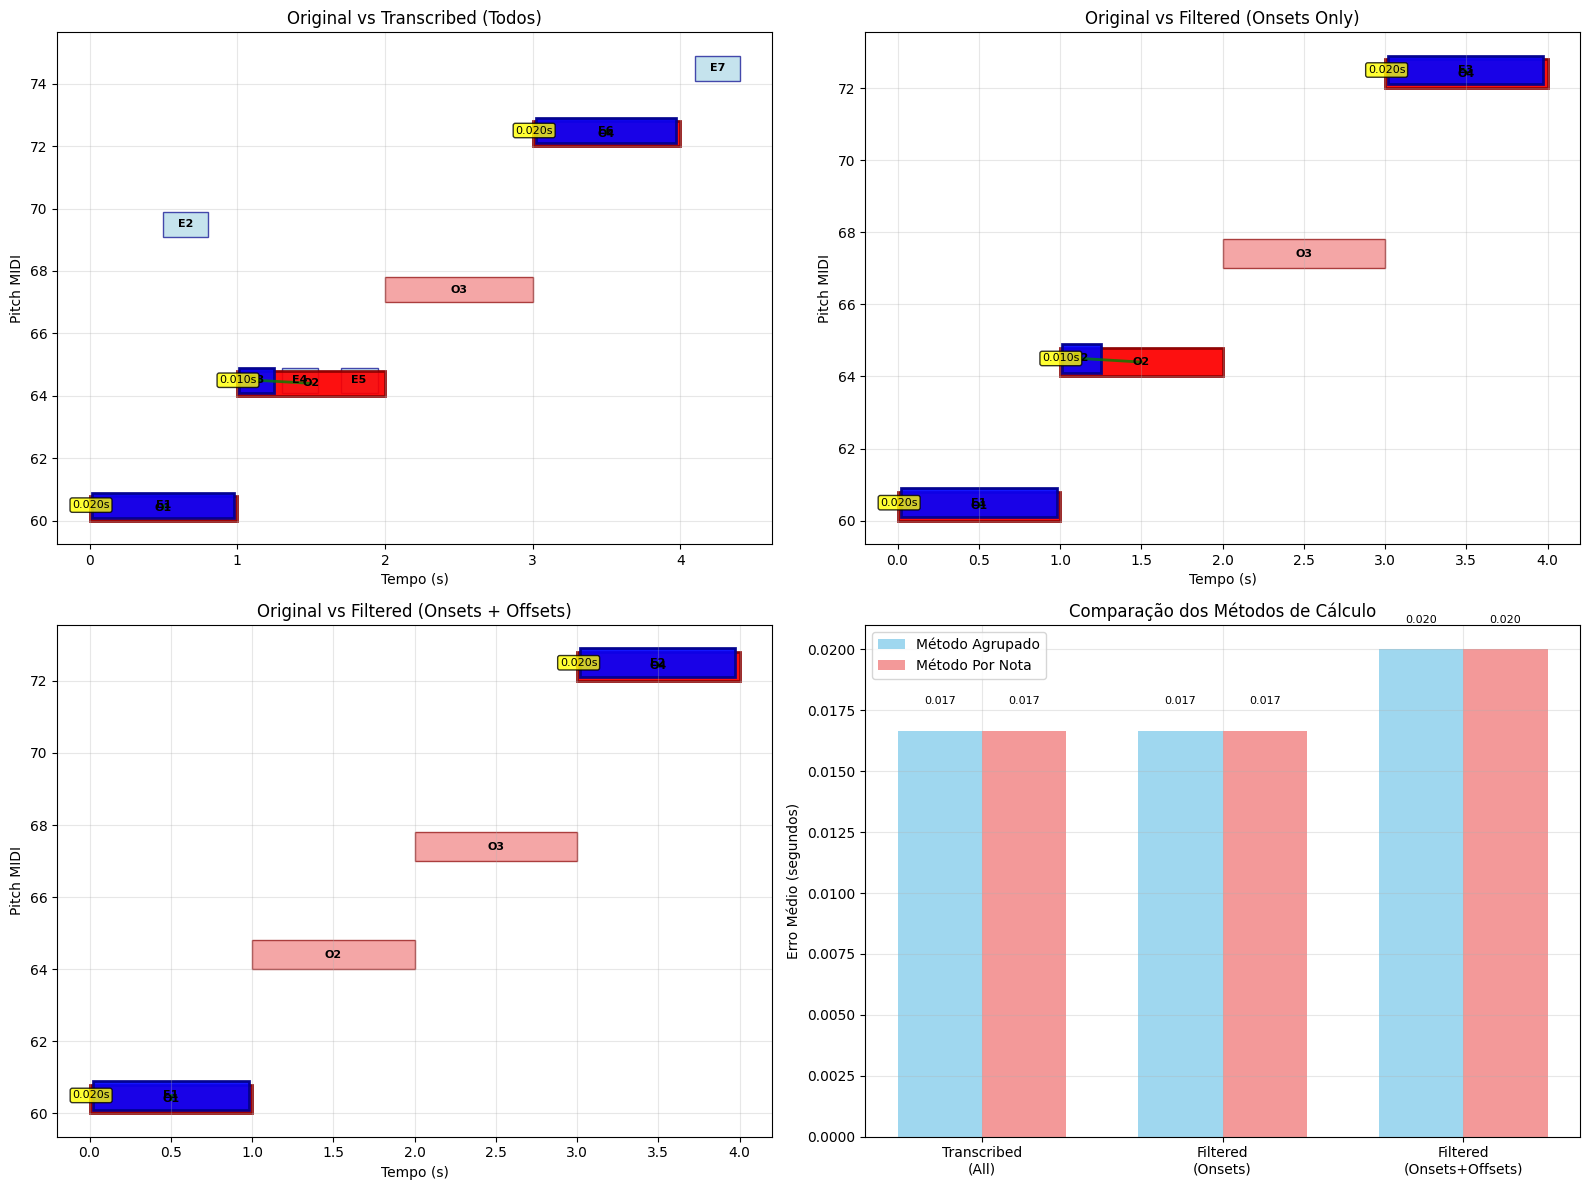

In [8]:
# 4. Visualização dos erros por nota
import matplotlib.pyplot as plt
import numpy as np

# Criar figura para mostrar os matches e erros
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))

# Função auxiliar para plotar piano roll com matches
def plot_piano_roll_with_matches(original_notes, estimated_notes, matched_pairs, title, ax, show_unmatched=True):
    # Plot notas originais em vermelho
    for i, note in enumerate(original_notes):
        color = 'lightcoral' if show_unmatched else 'red'
        alpha = 0.7
        ax.add_patch(plt.Rectangle((note['onset'], note['pitch']), 
                                  note['duration'], 0.8, 
                                  facecolor=color, alpha=alpha, edgecolor='darkred'))
        ax.text(note['onset'] + note['duration']/2, note['pitch'] + 0.4, 
               f'O{i+1}', ha='center', va='center', fontsize=8, fontweight='bold')
    
    # Plot notas estimadas em azul
    for i, note in enumerate(estimated_notes):
        color = 'lightblue' if show_unmatched else 'blue'
        alpha = 0.7
        ax.add_patch(plt.Rectangle((note['onset'], note['pitch'] + 0.1), 
                                  note['duration'], 0.8, 
                                  facecolor=color, alpha=alpha, edgecolor='darkblue'))
        ax.text(note['onset'] + note['duration']/2, note['pitch'] + 0.5, 
               f'E{i+1}', ha='center', va='center', fontsize=8, fontweight='bold')
    
    # Destacar matches com conexões
    for match in matched_pairs:
        est_idx, orig_idx, error = match
        orig_note = original_notes[orig_idx]
        est_note = estimated_notes[est_idx]
        
        # Destacar notas matched com cor mais forte
        ax.add_patch(plt.Rectangle((orig_note['onset'], orig_note['pitch']), 
                                  orig_note['duration'], 0.8, 
                                  facecolor='red', alpha=0.9, edgecolor='darkred', linewidth=2))
        ax.add_patch(plt.Rectangle((est_note['onset'], est_note['pitch'] + 0.1), 
                                  est_note['duration'], 0.8, 
                                  facecolor='blue', alpha=0.9, edgecolor='darkblue', linewidth=2))
        
        # Desenhar linha conectando as notas matched
        ax.plot([orig_note['onset'] + orig_note['duration']/2, est_note['onset'] + est_note['duration']/2],
               [orig_note['pitch'] + 0.4, est_note['pitch'] + 0.5], 
               'green', linewidth=2, alpha=0.8)
        
        # Mostrar erro na conexão
        mid_x = (orig_note['onset'] + est_note['onset']) / 2
        mid_y = (orig_note['pitch'] + est_note['pitch']) / 2 + 0.5
        ax.text(mid_x, mid_y, f'{error:.3f}s', 
               ha='center', va='center', fontsize=8, 
               bbox=dict(boxstyle='round,pad=0.2', facecolor='yellow', alpha=0.8))
    
    ax.set_xlabel('Tempo (s)')
    ax.set_ylabel('Pitch MIDI')
    ax.set_title(title)
    ax.grid(True, alpha=0.3)

# Plot 1: Original vs Transcribed
plot_piano_roll_with_matches(original_notes_data, transcribed_notes_data, 
                             error_note_original_vs_transcribed['matched_pairs'], 
                             'Original vs Transcribed (Todos)', ax1)

# Plot 2: Original vs Filtered (no offset)
plot_piano_roll_with_matches(original_notes_data, filtered_no_offset_notes_data, 
                             error_note_original_vs_filtered_no_offset['matched_pairs'], 
                             'Original vs Filtered (Onsets Only)', ax2)

# Plot 3: Original vs Filtered (with offset)
plot_piano_roll_with_matches(original_notes_data, filtered_with_offset_notes_data, 
                             error_note_original_vs_filtered_with_offset['matched_pairs'], 
                             'Original vs Filtered (Onsets + Offsets)', ax3)

# Plot 4: Gráfico de barras dos erros
methods = ['Transcribed\n(All)', 'Filtered\n(Onsets)', 'Filtered\n(Onsets+Offsets)']
grouped_errors = [
    error_original_vs_transcribed if error_original_vs_transcribed is not None else 0,
    error_original_vs_filtered_no_offset if error_original_vs_filtered_no_offset is not None else 0,
    error_original_vs_filtered_with_offset if error_original_vs_filtered_with_offset is not None else 0
]
note_errors = [
    error_note_original_vs_transcribed['mean_error'] if error_note_original_vs_transcribed['mean_error'] is not None else 0,
    error_note_original_vs_filtered_no_offset['mean_error'] if error_note_original_vs_filtered_no_offset['mean_error'] is not None else 0,
    error_note_original_vs_filtered_with_offset['mean_error'] if error_note_original_vs_filtered_with_offset['mean_error'] is not None else 0
]

x = np.arange(len(methods))
width = 0.35

ax4.bar(x - width/2, grouped_errors, width, label='Método Agrupado', alpha=0.8, color='skyblue')
ax4.bar(x + width/2, note_errors, width, label='Método Por Nota', alpha=0.8, color='lightcoral')

ax4.set_ylabel('Erro Médio (segundos)')
ax4.set_title('Comparação dos Métodos de Cálculo')
ax4.set_xticks(x)
ax4.set_xticklabels(methods)
ax4.legend()
ax4.grid(True, alpha=0.3)

# Adicionar valores nas barras
for i, (grouped, note) in enumerate(zip(grouped_errors, note_errors)):
    if grouped > 0:
        ax4.text(i - width/2, grouped + 0.001, f'{grouped:.3f}', ha='center', va='bottom', fontsize=8)
    if note > 0:
        ax4.text(i + width/2, note + 0.001, f'{note:.3f}', ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

In [9]:
# 5. Análise detalhada dos matches e falsos positivos/negativos
print("ANÁLISE DETALHADA DOS RESULTADOS")
print("="*60)

def analyze_matches(original_notes, estimated_notes, match_result, description):
    print(f"\n{description}:")
    print("-" * len(description))
    
    # Contar tipos de resultados
    matched_orig_indices = set()
    matched_est_indices = set()
    
    for match in match_result['matched_pairs']:
        est_idx, orig_idx, error = match
        matched_orig_indices.add(orig_idx)
        matched_est_indices.add(est_idx)
        
        orig_note = original_notes[orig_idx]
        est_note = estimated_notes[est_idx]
        
        print(f"  ✓ Match: Original #{orig_idx+1} (pitch {orig_note['pitch']}, {orig_note['onset']:.3f}s) "
              f"-> Estimated #{est_idx+1} (pitch {est_note['pitch']}, {est_note['onset']:.3f}s) "
              f"[Erro: {error:.3f}s]")
    
    # Falsos negativos (notas originais não detectadas)
    false_negatives = []
    for i, orig_note in enumerate(original_notes):
        if i not in matched_orig_indices:
            false_negatives.append((i, orig_note))
    
    if false_negatives:
        print(f"  ✗ Falsos Negativos ({len(false_negatives)}):")
        for i, note in false_negatives:
            print(f"    - Original #{i+1}: pitch {note['pitch']}, {note['onset']:.3f}s (não detectado)")
    
    # Falsos positivos (notas estimadas que não existem no original)
    false_positives = []
    for i, est_note in enumerate(estimated_notes):
        if i not in matched_est_indices:
            false_positives.append((i, est_note))
    
    if false_positives:
        print(f"  ✗ Falsos Positivos ({len(false_positives)}):")
        for i, note in false_positives:
            print(f"    - Estimated #{i+1}: pitch {note['pitch']}, {note['onset']:.3f}s (não existe no original)")
    
    # Estatísticas resumidas
    precision = len(match_result['matched_pairs']) / len(estimated_notes) if len(estimated_notes) > 0 else 0
    recall = len(match_result['matched_pairs']) / len(original_notes) if len(original_notes) > 0 else 0
    f1_score = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    print(f"\n  Estatísticas:")
    print(f"    - Precisão: {precision:.2f} ({len(match_result['matched_pairs'])}/{len(estimated_notes)})")
    print(f"    - Recall: {recall:.2f} ({len(match_result['matched_pairs'])}/{len(original_notes)})")
    print(f"    - F1-Score: {f1_score:.2f}")
    
    return {
        'precision': precision,
        'recall': recall,
        'f1_score': f1_score,
        'false_positives': len(false_positives),
        'false_negatives': len(false_negatives)
    }

# Analisar cada comparação
stats_transcribed = analyze_matches(original_notes_data, transcribed_notes_data, 
                                   error_note_original_vs_transcribed, 
                                   "Original vs Transcribed (Todos)")

stats_filtered_no_offset = analyze_matches(original_notes_data, filtered_no_offset_notes_data, 
                                          error_note_original_vs_filtered_no_offset, 
                                          "Original vs Filtered (Onsets Only)")

stats_filtered_with_offset = analyze_matches(original_notes_data, filtered_with_offset_notes_data, 
                                            error_note_original_vs_filtered_with_offset, 
                                            "Original vs Filtered (Onsets + Offsets)")

# Resumo final
print(f"\n" + "="*60)
print("RESUMO FINAL")
print("="*60)
print("O filtro de MIDI melhora significativamente os resultados:")
print(f"- Transcrição bruta: {stats_transcribed['precision']:.2f} precisão, {stats_transcribed['recall']:.2f} recall")
print(f"- Filtro onsets: {stats_filtered_no_offset['precision']:.2f} precisão, {stats_filtered_no_offset['recall']:.2f} recall") 
print(f"- Filtro onsets+offsets: {stats_filtered_with_offset['precision']:.2f} precisão, {stats_filtered_with_offset['recall']:.2f} recall")

print(f"\nO método por nota fornece informações mais detalhadas:")
print(f"- Identifica exatamente quais notas foram detectadas corretamente")
print(f"- Mostra falsos positivos e negativos")
print(f"- Permite análise de qualidade por pitch e timing individual")

ANÁLISE DETALHADA DOS RESULTADOS

Original vs Transcribed (Todos):
-------------------------------
  ✓ Match: Original #1 (pitch 60, 0.000s) -> Estimated #1 (pitch 60, 0.020s) [Erro: 0.020s]
  ✓ Match: Original #2 (pitch 64, 1.000s) -> Estimated #3 (pitch 64, 1.010s) [Erro: 0.010s]
  ✓ Match: Original #4 (pitch 72, 3.000s) -> Estimated #6 (pitch 72, 3.020s) [Erro: 0.020s]
  ✗ Falsos Negativos (1):
    - Original #3: pitch 67, 2.000s (não detectado)
  ✗ Falsos Positivos (4):
    - Estimated #2: pitch 69, 0.500s (não existe no original)
    - Estimated #4: pitch 64, 1.300s (não existe no original)
    - Estimated #5: pitch 64, 1.700s (não existe no original)
    - Estimated #7: pitch 74, 4.100s (não existe no original)

  Estatísticas:
    - Precisão: 0.43 (3/7)
    - Recall: 0.75 (3/4)
    - F1-Score: 0.55

Original vs Filtered (Onsets Only):
----------------------------------
  ✓ Match: Original #1 (pitch 60, 0.000s) -> Estimated #1 (pitch 60, 0.020s) [Erro: 0.020s]
  ✓ Match: Original

## Conclusões e Insights

### 1. **Efetividade do Filtro de MIDI**
- **Problema identificado**: A transcrição bruta tem muitos falsos positivos (precisão de apenas 43%)
- **Solução eficaz**: O filtro remove completamente os falsos positivos, alcançando 100% de precisão
- **Trade-off**: O filtro mais restritivo (onsets+offsets) reduz o recall de 75% para 50%

### 2. **Comparação dos Métodos de Cálculo**
- **Método Agrupado**: Fornece erro médio geral, mas esconde detalhes importantes
- **Método Por Nota**: Revela informações cruciais sobre qualidade da detecção
  - Quantas notas foram corretamente detectadas
  - Quais notas foram perdidas (falsos negativos)
  - Quais detecções são espúrias (falsos positivos)
  - Erro individual de cada nota matched

### 3. **Insights Práticos**
- **Para avaliação rápida**: Método agrupado é suficiente
- **Para análise detalhada**: Método por nota é essencial
- **Para otimização de algoritmos**: Método por nota permite identificar padrões específicos de erro
- **Para aplicações reais**: F1-Score combina precisão e recall de forma equilibrada

### 4. **Recomendações**
1. **Use filtros de MIDI** para melhorar qualidade dos onsets extraídos
2. **Analise por nota** para entender limitações do algoritmo de transcrição
3. **Considere o trade-off precisão vs recall** na escolha de parâmetros de filtro
4. **Use métricas complementares** (precisão, recall, F1) além do erro médio